In [1]:
import numpy as np
from qutip import mcsolve, destroy, basis
from tqdm import tqdm

For the two-level system studied in the paper the evolution of the density matrix of the qubit (for $\hbar=1$) is given by the following Lindblad master equation

$$
\begin{align*}
\frac{\partial }{\partial t}\hat{\rho}(t) &= -i[\hat{H},\hat{\rho}(t)] + \frac{\gamma}{2} D(\hat{\sigma})[\hat{\rho}(t)] \\
&= -i[\hat{H},\hat{\rho}(t)] +  \gamma\hat{\sigma}\hat{\rho}(t)\hat{\sigma}^\dag - \frac{\gamma}{2}\{\hat{\sigma}^\dag\hat{\sigma}, \hat{\rho}(t)\} \\
&= -i[\hat{H},\hat{\rho}(t)] +  \gamma\hat{\sigma}\hat{\rho}(t)\hat{\sigma}^\dag - \frac{\gamma}{2}\hat{\sigma}^\dag\hat{\sigma}\hat{\rho}(t) - \frac{\gamma}{2}\hat{\sigma}^\dag\hat{\sigma}\hat{\rho}(t) \\
&= -i[\hat{H},\hat{\rho}(t)] +  \frac{1}{2}[2\gamma\hat{\sigma}\hat{\rho}(t)\hat{\sigma}^\dag - \gamma\hat{\sigma}^\dag\hat{\sigma}\hat{\rho}(t) - \gamma\hat{\sigma}^\dag\hat{\sigma}\hat{\rho}(t)]  \\ 
& \textrm{Define collapse operator: } \hat{C}=\sqrt{\gamma}\hat{\sigma} \\
&= -i[\hat{H},\hat{\rho}(t)] +  \frac{1}{2}[2\hat{C}\hat{\rho}(t)\hat{C}^\dag - \hat{C}^\dag\hat{C}\hat{\rho}(t) - \hat{C}^\dag\hat{C}\hat{\rho}(t)]

\end{align*}
$$

The [collapse operators](https://qutip.readthedocs.io/en/stable/guide/dynamics/dynamics-master.html) are used by `QuTiP` And the Hamiltonian $\hat{H}$ which describes the *unitary* dynamics of the systems' evolution is given by
$$
\begin{align*}
\hat{H} &= \Delta \hat{\sigma}^\dag \hat{\sigma} + \Omega (\hat{\sigma} + \hat{\sigma}^\dag)\\

&\text{where} \qquad \hat{\sigma} = \ket{0}\bra{1} = \ket{g}\bra{e}

\end{align*}
$$

The master equation can be [modified](https://doi.org/10.1103/PhysRevA.89.052110) to account for the use of a photon detector with quantum efficiency $\eta$, where $0 \leq \eta \leq 1$, by 

<!-- replacing the $\gamma\hat{\sigma}\hat{\rho}(t)\hat{\sigma}^\dag$ term with $\eta\gamma\hat{\sigma}\hat{\rho}(t)\hat{\sigma}^\dag + (1-\eta)\gamma\hat{\sigma}\hat{\rho}(t)\hat{\sigma}^\dag$ which gives the following master equation

$$
\begin{align*}
\frac{\partial }{\partial t}\hat{\rho}(t) &= -i[\hat{H},\hat{\rho}(t)] +  \eta\gamma\hat{\sigma}\hat{\rho}(t)\hat{\sigma}^\dag + (1-\eta)\gamma\hat{\sigma}\hat{\rho}(t)\hat{\sigma}^\dag - \frac{\gamma}{2}\{\hat{\sigma}^\dag\hat{\sigma}, \hat{\rho}(t)\} \\

&= -i[\hat{H},\hat{\rho}(t)] +  (\eta + (1-\eta))\gamma\hat{\sigma}\hat{\rho}(t)\hat{\sigma}^\dag - \frac{\gamma}{2}\{\hat{\sigma}^\dag\hat{\sigma}, \hat{\rho}(t)\}

\end{align*}
$$ -->


In [2]:
def to_time_delay(array: np.ndarray) -> np.ndarray:
    """
    Convert an array of values into an array of time delays between consecutive values.

    Args:
        array: Input array of values.

    Returns:
        numpy.ndarray: Array of time delays between consecutive values.

    """
    return np.concatenate((np.asarray([array[0]]), np.diff(array)))

In [3]:
# eta = 0.1
N = 2  # Hilbert space dimension of the qubit i.e. 2
a = destroy(N)  # lowering operator (annihilation operator)
psi0 = basis(N, 0)  # initial state of the qubit (ground state or |0> or |g>)
omega = 1.0  # Rabi frequency
gamma = 1.75  # excited state, |1> (|e>), decay rate

c_ops = []
c_ops.append(np.sqrt(gamma) * a)  # define collapse operators
# c_ops.append(np.sqrt(eta*gamma) * a)  # define collapse operator for lossy photodetector
# c_ops.append(np.sqrt((1-eta)*gamma) * a) 

num_jumps_keep = 48  # number of jumps/time delays to measure
num_jumps_sim = 60  # to actually run, we choose much larger than the number of clicks we plan to keep

num_trajectories = 10_000 

In [4]:
num_deltas = 40
delta_max = 2.1
deltas = np.linspace(0.0, delta_max, num_deltas)

jump_array = np.zeros((num_deltas, num_trajectories, num_jumps_keep))

In [5]:
for i, delta in tqdm(enumerate(deltas)):
    t_0 = 0
    # Estimate the final time to have, on average, njumpsSim jumps
    t_f = (
        num_jumps_sim
        * (4 * delta**2 + 8 * omega**2 + gamma**2)
        / (4 * gamma * omega**2)
    )
    tlist = [t_0, t_f]

    H = delta * a.dag() * a + omega * a + omega * a.dag()  # define Hamiltonian

    num_trajectories_remaining = num_trajectories

    jumpList = []
    trajs_to_complete = [[] for _ in range(num_trajectories)]
    trajs_completed = []

    while num_trajectories_remaining > 0:
        mc_trajectories = mcsolve(H, psi0, tlist, c_ops, [], num_trajectories_remaining, options={"progress_bar": False})

        time_array = mc_trajectories.col_times

        # Append the results into the trajectories in trajs_to_complete
        # NOTE: Appending different trajectories into a single one is only valid for the TLS, which gets reset to |0> after each jump
        for idx, times in enumerate(time_array):
            trajs_to_complete[idx] += list(to_time_delay(times))


        sizes = np.array([len(traj) for traj in trajs_to_complete])
        good_indexes = np.arange(num_trajectories_remaining)[sizes >= num_jumps_keep]
        bad_indexes = np.arange(num_trajectories_remaining)[sizes < num_jumps_keep]
        n_good_traj = len(good_indexes)
        num_trajectories_remaining = num_trajectories_remaining - n_good_traj

        # Trajectories with num_jumps_keep jumps are moved into trajs_completed
        for idx in good_indexes:
            trajs_completed += [trajs_to_complete[idx][:num_jumps_keep]]

        # Remove completed trajectory from trajs_to_complete
        trajs_to_complete = [trajs_to_complete[idx] for idx in bad_indexes]

    jump_array[i, :, :] = np.array(trajs_completed)

0it [00:00, ?it/s]/home/amanuelant/.local/lib/python3.10/site-packages/qutip/solver/solver_base.py:576: FutureWarning: e_ops will be keyword only from qutip 5.3 for all solver
  warnings.warn(
/home/amanuelant/.local/lib/python3.10/site-packages/qutip/solver/solver_base.py:576: FutureWarning: ntraj will be keyword only from qutip 5.3 for all solver
  warnings.warn(
40it [38:23, 57.60s/it]


(10000, 48)
16.382834475795 0.051682556582804295


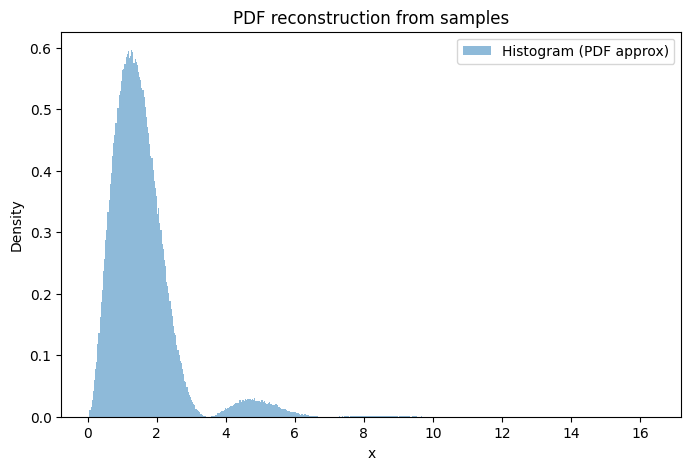

In [6]:
print(jump_array[0].shape)
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# Example: suppose you already have samples (replace with your list of samples)
samples = jump_array[0].flatten() #np.random.normal(loc=0, scale=1, size=2000)  # example data
print(samples.max(), samples.min())
# --- Histogram approximation of PDF ---
plt.figure(figsize=(8,5))
plt.hist(samples, bins=500, density=True, alpha=0.5, label="Histogram (PDF approx)")

# # --- Kernel Density Estimate (smooth PDF) ---
# kde = gaussian_kde(samples)
# x_vals = np.linspace(min(samples), max(samples), 500)
# plt.plot(x_vals, kde(x_vals), 'r-', lw=2, label="KDE estimate")

plt.xlabel("x")
plt.ylabel("Density")
plt.title("PDF reconstruction from samples")
plt.legend()
plt.show()


In [7]:
np.save(f'test-trajectories-1D-delta-nsets-10000-gamma-{gamma}-omega-{omega}.npy', jump_array)